In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

conn = snowflake.connector.connect(connection_name="criteo_svc")
df = conn.cursor().execute(
    "SELECT * FROM uplift SAMPLE BERNOULLI (21.5) SEED (42)"
).fetch_pandas_all()
df.columns = df.columns.str.lower()

features = [f"f{i}" for i in range(12)]
print(df.shape)
print(df.treatment.mean(), df.visit.mean())

(3007255, 17)
0.8497274092153808 0.04694114732538478


In [3]:
train, test = train_test_split(
    df, test_size=0.3, random_state=42,
    stratify=df["treatment"].astype(str) + df["visit"].astype(str)
)
print(len(train), len(test))

2105078 902177


In [4]:
params = dict(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", n_jobs=-1, eval_metric="logloss",
)

tr_t = train[train.treatment == 1]
tr_c = train[train.treatment == 0]

m_treat = XGBClassifier(**params).fit(tr_t[features], tr_t["visit"])
m_ctrl  = XGBClassifier(**params).fit(tr_c[features], tr_c["visit"])

test = test.copy()
test["p_treat"] = m_treat.predict_proba(test[features])[:, 1]
test["p_ctrl"]  = m_ctrl.predict_proba(test[features])[:, 1]
test["uplift"]  = test["p_treat"] - test["p_ctrl"]

test["uplift"].describe()

count    902177.000000
mean          0.007614
std           0.028157
min          -0.550583
25%          -0.000066
50%           0.000384
75%           0.002615
max           0.588766
Name: uplift, dtype: float64

In [5]:
m_resp = XGBClassifier(**params).fit(train[features], train["visit"])
test["p_visit"] = m_resp.predict_proba(test[features])[:, 1]

In [6]:
def qini(d, score_col):
    d = d.sort_values(score_col, ascending=False).reset_index(drop=True)
    n_t = d["treatment"].cumsum()
    n_c = (1 - d["treatment"]).cumsum()
    y_t = (d["visit"] * d["treatment"]).cumsum()
    y_c = (d["visit"] * (1 - d["treatment"])).cumsum()
    q = (y_t - y_c * n_t / n_c.replace(0, np.nan)).fillna(0).to_numpy()
    share = np.arange(1, len(d) + 1) / len(d)
    return share, q

share, q_uplift = qini(test, "uplift")
_,     q_resp   = qini(test, "p_visit")
q_random = share * q_uplift[-1]

def area_over_random(q):
    return np.trapezoid(q - q_random, share)

def kept_at(q, pct):
    return q[int(pct * len(q)) - 1] / q[-1]

print("Qini coefficient, uplift model:  ", round(area_over_random(q_uplift)))
print("Qini coefficient, response model:", round(area_over_random(q_resp)))
for pct in [0.1, 0.2, 0.3, 0.5]:
    print(f"Target top {int(pct*100)}%: uplift model keeps {kept_at(q_uplift, pct):.0%}, "
          f"response model keeps {kept_at(q_resp, pct):.0%} of incremental visits")

Qini coefficient, uplift model:   2636
Qini coefficient, response model: 2641
Target top 10%: uplift model keeps 55%, response model keeps 47% of incremental visits
Target top 20%: uplift model keeps 76%, response model keeps 73% of incremental visits
Target top 30%: uplift model keeps 83%, response model keeps 85% of incremental visits
Target top 50%: uplift model keeps 92%, response model keeps 95% of incremental visits


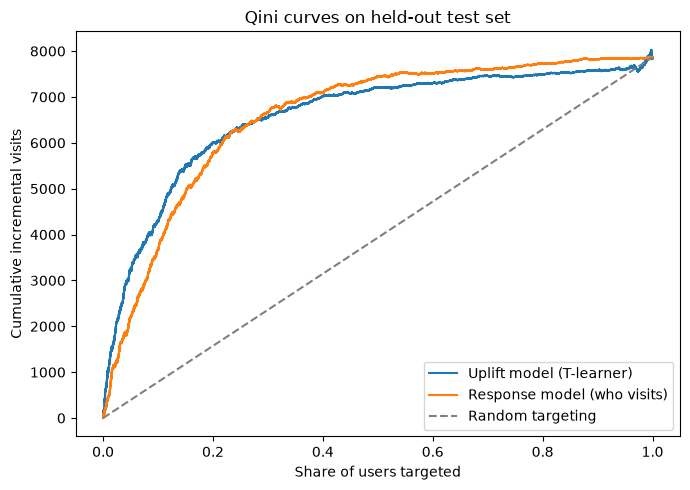

In [7]:
plt.figure(figsize=(7, 5))
plt.plot(share, q_uplift, label="Uplift model (T-learner)")
plt.plot(share, q_resp, label="Response model (who visits)")
plt.plot(share, q_random, "--", color="gray", label="Random targeting")
plt.xlabel("Share of users targeted")
plt.ylabel("Cumulative incremental visits")
plt.title("Qini curves on held-out test set")
plt.legend()
plt.tight_layout()
plt.savefig("../data/qini_curve.png", dpi=150)
plt.show()

In [8]:
idx = np.linspace(0, len(share) - 1, 101).astype(int)
pd.DataFrame({
    "share_targeted": share[idx],
    "uplift_model": q_uplift[idx],
    "response_model": q_resp[idx],
    "random": q_random[idx],
}).to_csv("../data/qini_curve.csv", index=False)

test[["user_id", "treatment", "visit", "conversion",
      "uplift", "p_visit"]].to_parquet("../data/test_scores.parquet")